#### Mpho Hadebe
#### CSC2042S ASSIGNMENT 1 - Perceptron Image classification


## 1. Data loading & Processing


## 1.1 GreyScale

In [3]:
import os
import numpy as np
from PIL import Image

# load data function
def load_data(data_dir):
    X = []
    y = []

    classes = sorted(os.listdir(data_dir))

    for label, class_name in enumerate(classes):
        class_dir = os.path.join(data_dir, class_name)

        if not os.path.isdir(class_dir):
            continue

        for file in os.listdir(class_dir):
            file_path = os.path.join(class_dir, file)

            image = Image.open(file_path)
            image = np.array(image)

            X.append(image.flatten())
            y.append(label)

    return np.array(X), np.array(y)

##### What X and y are

##### X is a 2D matrix holding your image data, where:

##### Each row represents one image
##### Each column represents one pixel value from that image (after flattening)
##### Shape: (number_of_images, number_of_pixels)

##### y is a 1D vector holding the labels, where:

##### Each entry is an integer from 0–9, identifying which of the 10 Simpsons characters that image depicts
##### Shape: (number_of_images,)
##### Entry y[i] is the correct label for the image represented by row X[i] — they stay aligned by position/index throughout.

#### READING AND SPLITTING DATA

In [4]:
from sklearn.model_selection import train_test_split

gray_X, gray_y = load_data("A2-dataset/dataset/grayscale/train")

gray_X_train, gray_X_valid, gray_y_train, gray_y_valid = train_test_split(
    gray_X,
    gray_y,
    test_size=0.2,
    random_state=42,
    stratify=gray_y
)

gray_X_test, gray_y_test = load_data("A2-dataset/dataset/grayscale/test")


## 1.2 RGB

In [5]:
from sklearn.model_selection import train_test_split

rgb_X, rgb_y = load_data(
    "A2-dataset/dataset/rgb/train"
)

rgb_X_train, rgb_X_valid, rgb_y_train, rgb_y_valid = train_test_split(
    rgb_X,
    rgb_y,
    test_size=0.2,
    random_state=42,
    stratify=rgb_y
)

rgb_X_test, rgb_y_test = load_data("A2-dataset/dataset/rgb/test")

## 2. Multi-class perceptron implementation & Training

In [6]:
import numpy as np

class BinaryPerceptron:

    def __init__(self, n_features, learning_rate=0.01):
        self.weights = np.full(n_features, 0.1)
        self.bias = 0.1
        self.learning_rate = learning_rate

    def score(self, X):
        return np.dot(X, self.weights) + self.bias

    def predict(self, X):
        if self.score(X) >= 0:
            return 1
        else:
            return 0

    def train(self, X, y, epochs):

        for epoch in range(epochs):

            order = np.random.permutation(len(X))
            errors = 0

            for i in order:

                prediction = self.predict(X[i])

                if prediction != y[i]:

                    error = y[i] - prediction

                    self.weights += (
                        self.learning_rate * error * X[i]
                    )

                    self.bias += self.learning_rate * error

                    errors += 1

           


class MultiClassPerceptron:

    def __init__(self, n_features, num_classes=10, learning_rate=0.01):

        self.perceptrons = []

        for i in range(num_classes):
            self.perceptrons.append(
                BinaryPerceptron(n_features, learning_rate)
            )

    def train(self, X_train, y_train, X_valid, y_valid, epochs):

        for class_number in range(10):

            binary_y = (y_train == class_number).astype(int)

            self.perceptrons[class_number].train(
                X_train,
                binary_y,
                epochs
            )

        predictions = self.predict(X_valid)
        accuracy = np.mean(predictions == y_valid)

        print("Validation accuracy:", accuracy)

    def train_early_stopping(
        self,
        X_train,
        y_train,
        X_valid,
        y_valid,
        max_epochs=50,
        patience=5
    ):

        best_accuracy = 0
        best_weights = []
        best_biases = []
        no_improvement = 0

        for epoch in range(max_epochs):

            for class_number in range(10):

                binary_y = (y_train == class_number).astype(int)

                order = np.random.permutation(len(X_train))

                for i in order:

                    prediction = self.perceptrons[class_number].predict(
                        X_train[i]
                    )

                    error = binary_y[i] - prediction

                    if error != 0:

                        self.perceptrons[class_number].weights += (
                            self.perceptrons[class_number].learning_rate
                            * error
                            * X_train[i]
                        )

                        self.perceptrons[class_number].bias += (
                            self.perceptrons[class_number].learning_rate
                            * error
                        )

            predictions = self.predict(X_valid)

            accuracy = np.mean(predictions == y_valid)

            print(
                "Epoch:", epoch + 1,
                "Validation accuracy:", accuracy
            )

            if accuracy > best_accuracy:

                best_accuracy = accuracy
                no_improvement = 0

                best_weights = []

                for perceptron in self.perceptrons:
                    best_weights.append(perceptron.weights.copy())

                best_biases = []

                for perceptron in self.perceptrons:
                    best_biases.append(perceptron.bias)

            else:
                no_improvement += 1

            if no_improvement >= patience:
                print("Early stopping")
                break

        for i in range(10):
            self.perceptrons[i].weights = best_weights[i]
            self.perceptrons[i].bias = best_biases[i]

        print("Best validation accuracy:", best_accuracy)

    def predict(self, X):

        predictions = []

        for image in X:

            scores = []

            for perceptron in self.perceptrons:
                scores.append(perceptron.score(image))

            prediction = np.argmax(scores)

            predictions.append(prediction)

        return np.array(predictions)

##### Run Task 3 for greyScale

In [7]:
print("========== GRAYSCALE ==========")

gray_model = MultiClassPerceptron(
    gray_X_train.shape[1],
    learning_rate=0.01
)

gray_model.train_early_stopping(
    gray_X_train,
    gray_y_train,
    gray_X_valid,
    gray_y_valid,
    max_epochs=50,
    patience=5
)

========== GRAYSCALE ==========
Epoch: 1 Validation accuracy: 0.1725
Epoch: 2 Validation accuracy: 0.14
Epoch: 3 Validation accuracy: 0.193125
Epoch: 4 Validation accuracy: 0.11875
Epoch: 5 Validation accuracy: 0.228125
Epoch: 6 Validation accuracy: 0.22125
Epoch: 7 Validation accuracy: 0.143125
Epoch: 8 Validation accuracy: 0.121875
Epoch: 9 Validation accuracy: 0.18125
Epoch: 10 Validation accuracy: 0.2275
Early stopping
Best validation accuracy: 0.228125


##### Run task 3 for RGB

In [6]:
print("========== RGB ==========")

rgb_model = MultiClassPerceptron(
    rgb_X_train.shape[1],
    learning_rate=0.01
)

rgb_model.train_early_stopping(
    rgb_X_train,
    rgb_y_train,
    rgb_X_valid,
    rgb_y_valid,
    max_epochs=50,
    patience=5
)

========== RGB ==========
Epoch: 1 Validation accuracy: 0.39
Epoch: 2 Validation accuracy: 0.289375
Epoch: 3 Validation accuracy: 0.3325
Epoch: 4 Validation accuracy: 0.308125
Epoch: 5 Validation accuracy: 0.3825
Epoch: 6 Validation accuracy: 0.320625
Early stopping
Best validation accuracy: 0.39


## 4.Hyperparameter tuning

In [8]:
import numpy as np
import matplotlib.pyplot as plt


# -----------------------------
# Normalisation
# -----------------------------

def normalize_train(X, method):

    if method == "none":
        return X, None, None

    if method == "minmax":
        return X / 255.0, None, None

    if method == "zscore":
        mean = np.mean(X, axis=0)
        std = np.std(X, axis=0)

        std[std == 0] = 1

        X = (X - mean) / std

        return X, mean, std


def normalize_valid(X, method, mean=None, std=None):

    if method == "none":
        return X

    if method == "minmax":
        return X / 255.0

    if method == "zscore":
        return (X - mean) / std


# -----------------------------
# Task 4 grid search
# -----------------------------

def tune_model(X_train, y_train, X_valid, y_valid):

    learning_rates = [0.0001, 0.001, 0.01, 0.1]

    normalizations = [
        "none",
        "minmax",
        "zscore"
    ]

    results = []

    for learning_rate in learning_rates:

        for normalization in normalizations:

            print("Learning rate:", learning_rate)
            print("Normalization:", normalization)

            # Normalise training data
            X_train_norm, mean, std = normalize_train(
                X_train,
                normalization
            )

            # Use training statistics on validation data
            X_valid_norm = normalize_valid(
                X_valid,
                normalization,
                mean,
                std
            )

            # Create a fresh model
            model = MultiClassPerceptron(
                X_train_norm.shape[1],
                learning_rate=learning_rate
            )

            # Train model
            model.train(
                X_train_norm,
                y_train,
                X_valid_norm,
                y_valid,
                epochs=50
            )

            # Validation prediction
            predictions = model.predict(X_valid_norm)

            accuracy = np.mean(predictions == y_valid)

            print("Validation accuracy:", accuracy)
            print()

            results.append([
                learning_rate,
                normalization,
                accuracy
            ])

    return results

### 4.1 Greyscale hyperparameter tuning

In [9]:
gray_results = tune_model(
    gray_X_train,
    gray_y_train,
    gray_X_valid,
    gray_y_valid
)

Learning rate: 0.0001
Normalization: none
Validation accuracy: 0.189375
Validation accuracy: 0.189375

Learning rate: 0.0001
Normalization: minmax
Validation accuracy: 0.24125
Validation accuracy: 0.24125

Learning rate: 0.0001
Normalization: zscore
Validation accuracy: 0.21625
Validation accuracy: 0.21625

Learning rate: 0.001
Normalization: none
Validation accuracy: 0.218125
Validation accuracy: 0.218125

Learning rate: 0.001
Normalization: minmax
Validation accuracy: 0.186875
Validation accuracy: 0.186875

Learning rate: 0.001
Normalization: zscore
Validation accuracy: 0.221875
Validation accuracy: 0.221875

Learning rate: 0.01
Normalization: none
Validation accuracy: 0.241875
Validation accuracy: 0.241875

Learning rate: 0.01
Normalization: minmax
Validation accuracy: 0.2375
Validation accuracy: 0.2375

Learning rate: 0.01
Normalization: zscore
Validation accuracy: 0.224375
Validation accuracy: 0.224375

Learning rate: 0.1
Normalization: none
Validation accuracy: 0.2175
Validation 

#### finding the best greyscale setting

In [12]:
best_gray = max(
    gray_results,
    key=lambda x: x[2]
)

print("Best grayscale model")
print("Learning rate:", best_gray[0])
print("Normalization:", best_gray[1])
print("Validation accuracy:", best_gray[2])

Best grayscale model
Learning rate: 0.01
Normalization: none
Validation accuracy: 0.241875


### 4.2 RGB hyperparameter tuning

In [11]:
rgb_results = tune_model(
    rgb_X_train,
    rgb_y_train,
    rgb_X_valid,
    rgb_y_valid
)

Learning rate: 0.0001
Normalization: none
Validation accuracy: 0.409375
Validation accuracy: 0.409375

Learning rate: 0.0001
Normalization: minmax
Validation accuracy: 0.399375
Validation accuracy: 0.399375

Learning rate: 0.0001
Normalization: zscore
Validation accuracy: 0.389375
Validation accuracy: 0.389375

Learning rate: 0.001
Normalization: none
Validation accuracy: 0.345625
Validation accuracy: 0.345625

Learning rate: 0.001
Normalization: minmax
Validation accuracy: 0.356875
Validation accuracy: 0.356875

Learning rate: 0.001
Normalization: zscore
Validation accuracy: 0.368125
Validation accuracy: 0.368125

Learning rate: 0.01
Normalization: none
Validation accuracy: 0.40125
Validation accuracy: 0.40125

Learning rate: 0.01
Normalization: minmax
Validation accuracy: 0.39
Validation accuracy: 0.39

Learning rate: 0.01
Normalization: zscore
Validation accuracy: 0.37
Validation accuracy: 0.37

Learning rate: 0.1
Normalization: none
Validation accuracy: 0.399375
Validation accuracy

#### finding the best RGB setting

In [13]:
best_rgb = max(
    rgb_results,
    key=lambda x: x[2]
)

print("Best RGB model")
print("Learning rate:", best_rgb[0])
print("Normalization:", best_rgb[1])
print("Validation accuracy:", best_rgb[2])

Best RGB model
Learning rate: 0.0001
Normalization: none
Validation accuracy: 0.409375


## 4.3 Final winning models 


### 4.3.1 Winning greyScale model


In [15]:

gray_model = MultiClassPerceptron(
    gray_X_train.shape[1],
    learning_rate=0.01
)

gray_model.train_early_stopping(
    gray_X_train,
    gray_y_train,
    gray_X_valid,
    gray_y_valid,
    max_epochs=50,
    patience=5
)

Epoch: 1 Validation accuracy: 0.105
Epoch: 2 Validation accuracy: 0.17
Epoch: 3 Validation accuracy: 0.178125
Epoch: 4 Validation accuracy: 0.17
Epoch: 5 Validation accuracy: 0.2275
Epoch: 6 Validation accuracy: 0.174375
Epoch: 7 Validation accuracy: 0.2
Epoch: 8 Validation accuracy: 0.225
Epoch: 9 Validation accuracy: 0.17
Epoch: 10 Validation accuracy: 0.18625
Early stopping
Best validation accuracy: 0.2275


### 4.3.2 Winning RGB model

In [16]:
# Winning RGB model
rgb_model = MultiClassPerceptron(
    rgb_X_train.shape[1],
    learning_rate=0.0001
)

rgb_model.train_early_stopping(
    rgb_X_train,
    rgb_y_train,
    rgb_X_valid,
    rgb_y_valid,
    max_epochs=50,
    patience=5
)

Epoch: 1 Validation accuracy: 0.283125
Epoch: 2 Validation accuracy: 0.204375
Epoch: 3 Validation accuracy: 0.3225
Epoch: 4 Validation accuracy: 0.374375
Epoch: 5 Validation accuracy: 0.395625
Epoch: 6 Validation accuracy: 0.314375
Epoch: 7 Validation accuracy: 0.396875
Epoch: 8 Validation accuracy: 0.2575
Epoch: 9 Validation accuracy: 0.378125
Epoch: 10 Validation accuracy: 0.35625
Epoch: 11 Validation accuracy: 0.303125
Epoch: 12 Validation accuracy: 0.3625
Early stopping
Best validation accuracy: 0.396875


### PLOTTING TASK 4 RESULTS

In [27]:
def plot_results(results, title):

    normalizations = ["none", "minmax", "zscore"]

    for normalization in normalizations:

        learning_rates = []
        accuracies = []

        for result in results:

            if result[1] == normalization:
                learning_rates.append(result[0])
                accuracies.append(result[2])

        plt.plot(
            learning_rates,
            accuracies,
            marker="o",
            label=normalization
        )

    plt.xscale("log")
    plt.xlabel("Learning rate")
    plt.ylabel("Validation accuracy")
    plt.title(title)
    plt.legend()
    plt.show()

##### FOR GREYSCALE

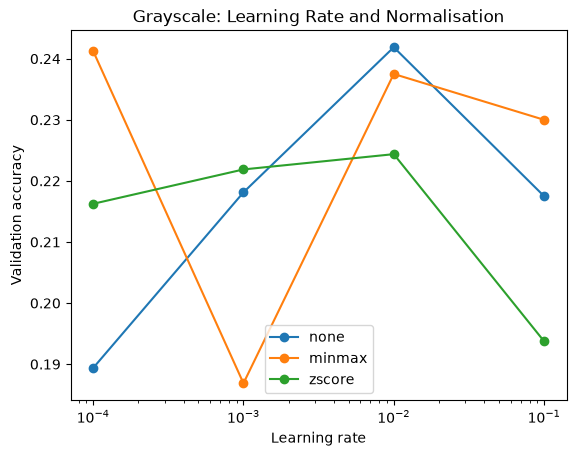

In [28]:
plot_results(
    gray_results,
    "Grayscale: Learning Rate and Normalisation"
)

##### FOR RGB

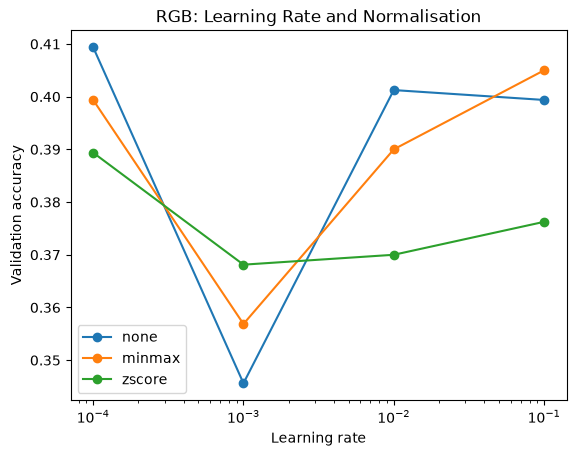

In [29]:
plot_results(
    rgb_results,
    "RGB: Learning Rate and Normalisation"
)

# 5. Evaluation

## 5.4 Evaluation

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

In [18]:
def evaluate_model(model, X, y, name):

    predictions = model.predict(X)

    accuracy = accuracy_score(y, predictions)

    precision, recall, f1, support = precision_recall_fscore_support(
        y,
        predictions,
        labels=np.arange(10),
        zero_division=0
    )

    print("\n" + name)
    print("-----------------------------")
    print("Accuracy:", accuracy)

    print("\nPer-class results:")
    print("Class    Precision    Recall    F1")

    for i in range(10):
        print(
            i,
            "      ",
            round(precision[i], 4),
            "       ",
            round(recall[i], 4),
            "   ",
            round(f1[i], 4)
        )

    return predictions

### 5.4.1 Evaluate the greyscale final model

In [21]:
gray_valid_predictions = evaluate_model(
    gray_model,
    gray_X_valid,
    gray_y_valid,
    "Grayscale Validation"
)


Grayscale Validation
-----------------------------
Accuracy: 0.2275

Per-class results:
Class    Precision    Recall    F1
0        0.1934         0.3312     0.2442
1        0.5161         0.1     0.1675
2        0.2973         0.1375     0.188
3        0.0769         0.0062     0.0116
4        0.1429         0.0312     0.0513
5        0.3109         0.4625     0.3719
6        0.1905         0.4     0.2581
7        0.1821         0.4312     0.256
8        0.2286         0.05     0.0821
9        0.2811         0.325     0.3014


In [23]:
gray_test_predictions = evaluate_model(
    gray_model,
    gray_X_test,
    gray_y_test,
    "Grayscale Test"
)


Grayscale Test
-----------------------------
Accuracy: 0.224

Per-class results:
Class    Precision    Recall    F1
0        0.2073         0.37     0.2657
1        0.5814         0.125     0.2058
2        0.2857         0.14     0.1879
3        0.2         0.015     0.0279
4        0.1961         0.05     0.0797
5        0.2917         0.455     0.3555
6        0.1779         0.37     0.2403
7        0.1435         0.3     0.1942
8        0.325         0.065     0.1083
9        0.28         0.35     0.3111


### 5.4.2 Evaluat the RGB final model

In [24]:
rgb_valid_predictions = evaluate_model(
    rgb_model,
    rgb_X_valid,
    rgb_y_valid,
    "RGB Validation"
)


RGB Validation
-----------------------------
Accuracy: 0.396875

Per-class results:
Class    Precision    Recall    F1
0        0.3168         0.3188     0.3178
1        0.5469         0.2188     0.3125
2        0.5357         0.1875     0.2778
3        0.8154         0.3312     0.4711
4        0.4857         0.2125     0.2957
5        0.6215         0.6875     0.6528
6        0.473         0.4375     0.4545
7        0.4672         0.3562     0.4043
8        0.3304         0.4625     0.3854
9        0.2359         0.7562     0.3596


In [25]:
rgb_test_predictions = evaluate_model(
    rgb_model,
    rgb_X_test,
    rgb_y_test,
    "RGB Test"
)


RGB Test
-----------------------------
Accuracy: 0.397

Per-class results:
Class    Precision    Recall    F1
0        0.3218         0.325     0.3234
1        0.5385         0.245     0.3368
2        0.5263         0.15     0.2335
3        0.6923         0.315     0.433
4        0.4175         0.215     0.2838
5        0.7171         0.735     0.7259
6        0.4725         0.43     0.4503
7        0.4595         0.34     0.3908
8        0.3079         0.465     0.3705
9        0.2423         0.75     0.3663


### 5.5 Confusion matrix function

In [30]:
def plot_confusion_matrix(y, predictions, title):

    matrix = confusion_matrix(
        y,
        predictions,
        labels=np.arange(10)
    )

    plt.figure(figsize=(8, 8))

    plt.imshow(matrix)

    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")

    plt.xticks(np.arange(10))
    plt.yticks(np.arange(10))

    plt.colorbar()

    plt.show()

### 5.5.1 GreyScale confusion matrix

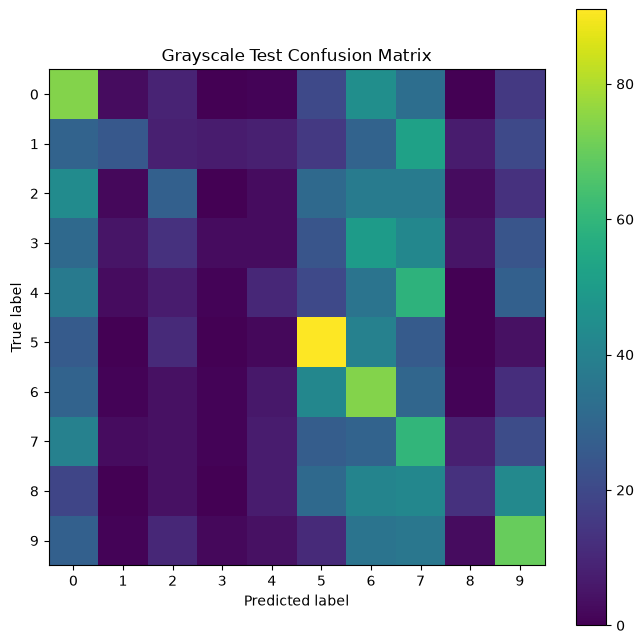

In [31]:
plot_confusion_matrix(
    gray_y_test,
    gray_test_predictions,
    "Grayscale Test Confusion Matrix"
)

### 5.5.2 RGB confusion matrix

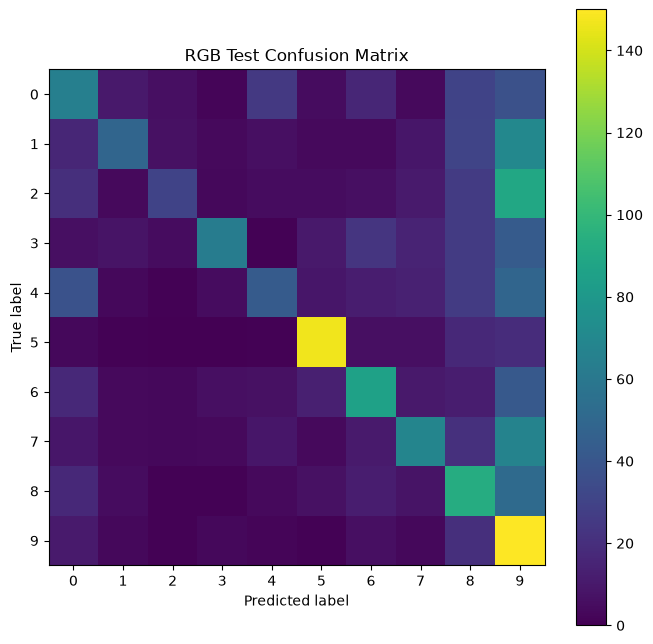

In [32]:
plot_confusion_matrix(
    rgb_y_test,
    rgb_test_predictions,
    "RGB Test Confusion Matrix"
)

## 7. Data Augmentation Analysis on RGB

In [33]:
from PIL import Image
import os
import numpy as np

def load_rgb_raw(folder):

    images = []
    labels = []

    classes = sorted(os.listdir(folder))

    for label, class_name in enumerate(classes):

        class_folder = os.path.join(folder, class_name)

        for filename in os.listdir(class_folder):

            filepath = os.path.join(class_folder, filename)

            image = Image.open(filepath).convert("RGB")

            image = np.array(image)

            images.append(image)
            labels.append(label)

    return np.array(images), np.array(labels)

### load Raw RGB training data

In [34]:
rgb_X_train_raw, rgb_y_train_raw = load_rgb_raw(
    "A2-dataset/dataset/rgb/test"
)

print(rgb_X_train_raw.shape)
print(rgb_y_train_raw.shape)

(2000, 28, 28, 3)
(2000,)


### 7.1.1 Brightness augmentation

In [35]:
def brightness_jitter(image):

    b = np.random.uniform(0.7, 1.3)

    image = image.astype(float) * b

    image = np.clip(image, 0, 255)

    return image.astype(np.uint8)

### 7.1.2 Rotation augmentation

In [36]:
def rotate_image(image):

    angle = np.random.uniform(-15, 15)

    pil_image = Image.fromarray(image)

    rotated = pil_image.rotate(angle)

    return np.array(rotated)

### 7.2 Create the Augmented dataset

In [37]:
def make_augmented_data(X, y, method):

    augmented_images = []

    for image in X:

        if method == "brightness":
            new_image = brightness_jitter(image)

        elif method == "rotation":
            new_image = rotate_image(image)

        augmented_images.append(new_image)

    augmented_images = np.array(augmented_images)

    X_combined = np.concatenate((X, augmented_images))
    y_combined = np.concatenate((y, y))

    return X_combined, y_combined

### 7.3 Flatten after augmentation

In [38]:
def flatten_images(X):

    return X.reshape(X.shape[0], -1)

### 7.4 Function to prepare each condition

none
→ original images
→ flatten

brightness
→ original + brightness copies
→ flatten

rotation
→ original + rotation copies
→ flatten

In [39]:
def prepare_task7_data(X_raw, y, method):

    if method == "none":
        X = X_raw
        labels = y

    else:
        X, labels = make_augmented_data(
            X_raw,
            y,
            method
        )

    X = flatten_images(X)

    return X, labels

### 7.5 Function to train one model

In [45]:
def run_task7_model(X_train, y_train, seed):

    np.random.seed(seed)

    model = MultiClassPerceptron(
        X_train.shape[1],
        learning_rate=0.01
    )

    model.train_early_stopping(
        X_train,
        y_train,
        rgb_X_valid,
        rgb_y_valid,
        max_epochs=50,
        patience=5
    )

    predictions = model.predict(rgb_X_test)

    accuracy = np.mean(predictions == rgb_y_test)

    return accuracy

In [41]:
seeds = [1, 2, 3, 4, 5]

conditions = [
    "none",
    "brightness",
    "rotation"
]

### 7.6 Run the experiment 

In [46]:
results = {}

for condition in conditions:

    print("\n==============================")
    print("Condition:", condition)
    print("==============================")

    X_condition, y_condition = prepare_task7_data(
        rgb_X_train_raw,
        rgb_y_train_raw,
        condition
    )

    print("Training data shape:", X_condition.shape)

    accuracies = []

    for seed in seeds:

        print("\nSeed:", seed)

        accuracy = run_task7_model(
            X_condition,
            y_condition,
            seed
        )

        accuracies.append(accuracy)

        print("Test accuracy:", accuracy)

    results[condition] = accuracies


Condition: none
Training data shape: (2000, 2352)

Seed: 1
Epoch: 1 Validation accuracy: 0.225625
Epoch: 2 Validation accuracy: 0.213125
Epoch: 3 Validation accuracy: 0.315625
Epoch: 4 Validation accuracy: 0.265
Epoch: 5 Validation accuracy: 0.29875
Epoch: 6 Validation accuracy: 0.32625
Epoch: 7 Validation accuracy: 0.2325
Epoch: 8 Validation accuracy: 0.3025
Epoch: 9 Validation accuracy: 0.290625
Epoch: 10 Validation accuracy: 0.340625
Epoch: 11 Validation accuracy: 0.33375
Epoch: 12 Validation accuracy: 0.293125
Epoch: 13 Validation accuracy: 0.29625
Epoch: 14 Validation accuracy: 0.355
Epoch: 15 Validation accuracy: 0.3475
Epoch: 16 Validation accuracy: 0.3125
Epoch: 17 Validation accuracy: 0.331875
Epoch: 18 Validation accuracy: 0.328125
Epoch: 19 Validation accuracy: 0.333125
Early stopping
Best validation accuracy: 0.355
Test accuracy: 0.7695

Seed: 2
Epoch: 1 Validation accuracy: 0.22875
Epoch: 2 Validation accuracy: 0.298125
Epoch: 3 Validation accuracy: 0.28875
Epoch: 4 Valid

### 7.7 Calculate the mean and the Standard deviation 

In [48]:
for condition in conditions:

    accuracies = results[condition]

    mean_accuracy = np.mean(accuracies)
    std_accuracy = np.std(accuracies)

    print("\n", condition)
    print("Mean test accuracy:", mean_accuracy)
    print("Standard deviation:", std_accuracy)


 none
Mean test accuracy: 0.6407
Standard deviation: 0.1006362757657496

 brightness
Mean test accuracy: 0.6314
Standard deviation: 0.08236467689489228

 rotation
Mean test accuracy: 0.5586
Standard deviation: 0.03921912798622631
